NOTES ON NEW FILE: I think this file is a little bit better organized and makes more consistent plots, I think. Plus, the final code block at the bottom can run on any data, just need to change the input name variable and then name for plotting if you want final plots based on that. Some finnicky stuff going on with the random seeds again, so be careful of that.

# Final Project: SNM in Space #

# MUST run Section (imports the data, begins the .ipynb file, saves X data and labels)

Basic Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.preprocessing import LabelEncoder

Read in the Data 

In [2]:
#Tier 0 base data
tier0_50 = pd.read_csv(".\\data\\tier0_ideal_ap9avg_sc50.csv")
tier0_75 = pd.read_csv(".\\data\\tier0_ideal_ap9avg_sc75.csv")
tier0_95 = pd.read_csv(".\\data\\tier0_ideal_ap9avg_sc95.csv")

FileNotFoundError: [Errno 2] No such file or directory: '.\\data\\tier0_ideal_ap9avg_sc50.csv'

In [ ]:
#Tier 1 data
tier1_50 = pd.read_csv(".\\data\\tier1_flatbg2hz_ap9avg_sc50.csv")

In [ ]:
#Tier 2 data
tier2_50 = pd.read_csv(".\\data\\tier2_flatbg2hz_selfbg010_ap9avg_sc50.csv")

In [ ]:
#Tier 3 data
tier3_50 = pd.read_csv(".\\data\\tier3_resp035_thr05_smear_ap9avg_sc50.csv")

In [ ]:
#Tier 4 data
tier4a_50 = pd.read_csv(".\\data\\tier4a_standoff5m_ap9avg_sc50.csv")
tier4c_50 = pd.read_csv(".\\data\\tier4c_standoff5m_panel0p5m_ap9avg_sc50.csv")

In [ ]:
#Tier 5 data
tier5a_50 =pd.read_csv(".\\data\\tier5a_highgt60_1e4_sc50.csv")
tier5b_50 =pd.read_csv(".\\data\\tier5b_lowgt60_1e2_sc50.csv")

In [ ]:
#Tier 6 data
tier6_50 = pd.read_csv(".\\data\\tier6_highgt60_dist_15m_sc50.csv")

General structure of all files is the same. 500 rows per material (small Al, large Al, vacuum, W, Pu). With these also labeled by class (Benign, high Z, SNM). Want to save this structure from any one file to call back on as a reference

In [ ]:
#Class labels are Benign, High Z, and SNM
class_labels= tier1_50['class_label'].values

#Material labels are G4_Al_small, G4_Al_large, G4_Galactic, G4_W, WGPu
# note we have to change the labels for the small and large aluminum to differentiate them
material_labels = tier1_50['snmMaterial'].values
material_labels[0:500] = 'G4_Al_small'
material_labels[500:1000] = 'G4_Al_large'

# create a variable called sample numbers for plotting
sample_numbers = np.linspace(1, len(class_labels), len(class_labels))

# encoded labels for later use
encoded_class_labels = LabelEncoder().fit_transform(class_labels)
encoded_material_labels = LabelEncoder().fit_transform(material_labels)
encoded_all_outputs = np.column_stack((encoded_class_labels, encoded_material_labels))

# generic X dataset. All columns after 8 are real data. First 2 columns are class and material labels, and the next 6 columns are metadata
X = tier0_50.iloc[:, 8:]

# feature labels
feature_labels = [X.columns[i] for i in range(X.shape[1])]

Plots to display original data organization

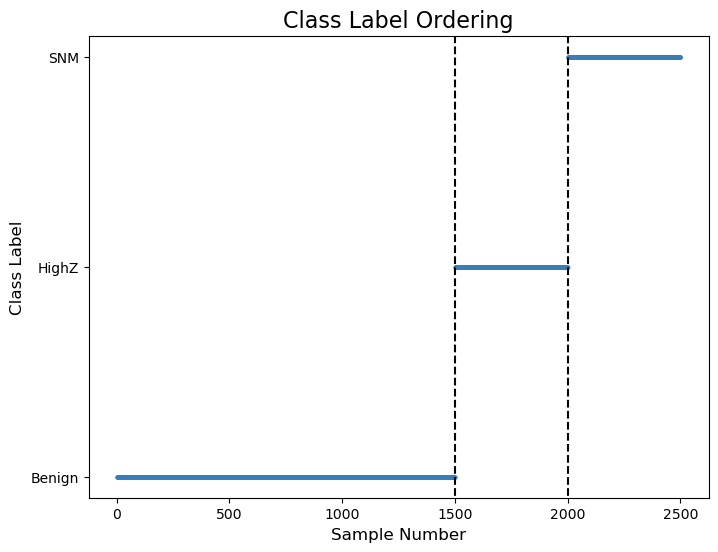

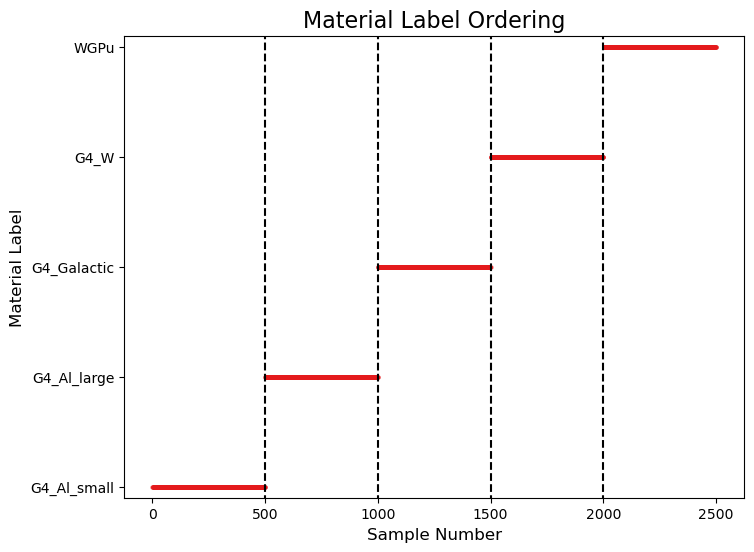

In [ ]:
# plot by class label
plt.figure(figsize=(8, 6))
plt.scatter(sample_numbers, class_labels, alpha=0.5, s=5, color='#377eb8')
plt.vlines(x=[1500, 2000], ymin=-0.25, ymax=2.25, color='k', linestyle='--', label='Class Boundary')
plt.ylim(-0.1, 2.1)
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('Class Label', fontsize=12)
plt.title('Class Label Ordering', fontsize=16)
plt.show()

#plot by material label
plt.figure(figsize=(8, 6))
plt.scatter(sample_numbers, material_labels, alpha=0.5, s=5, color='#e41a1c')
plt.vlines(x=[500, 1000, 1500, 2000], ymin=-0.25, ymax=4.25, color='k', linestyle='--', label='Class Boundary')
plt.ylim(-0.1, 4.1)
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('Material Label', fontsize=12)
plt.title('Material Label Ordering', fontsize=16)
plt.show()

# Begin Project Work: Testing on tier0 data #

### A) Unsupervised clustering ###

Save Inputs

In [ ]:
# All predictive data (Previous columns are sampling data, so I'm starting from column 8)
X_tier0 = tier0_50.iloc[:, 8:]

# Standardize the data
scaler = StandardScaler()
X_tier0_scaled = scaler.fit_transform(X_tier0)

Begin KMeans Clustering Option

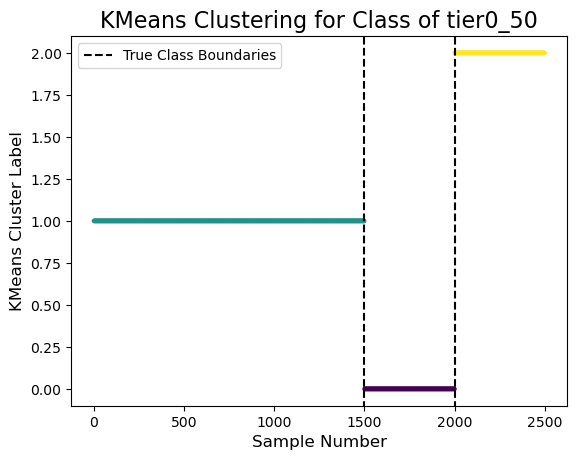

In [ ]:
# Testing 3 clusters, and comparing against the true class labels (3 classes)
km3 = KMeans(n_clusters=3, n_init=30)
km3.fit(X_tier0)
kmlabels3 = km3.labels_

plt.scatter(sample_numbers, kmlabels3, c=kmlabels3, alpha=0.5, s=5, cmap='viridis')
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('KMeans Cluster Label', fontsize=12)
plt.vlines(x=[1500, 2000], ymin=-.25, ymax = 2.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 2.1)
plt.title('KMeans Clustering for Class of tier0_50', fontsize=16)
plt.legend()
plt.show()

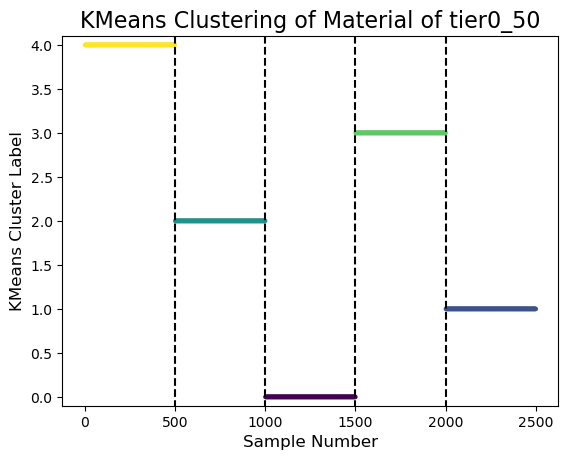

In [ ]:
# Testing 5 clusters, and comparing against the true material labels (5 materials)
km5 = KMeans(n_clusters=5, n_init=30, random_state=1)
km5.fit(X_tier0)
kmlabels5 = km5.labels_

plt.scatter(sample_numbers, kmlabels5, alpha=0.5, c=kmlabels5, s=5, cmap='viridis')
plt.vlines(x=[500, 1000, 1500, 2000], ymin=-.25, ymax = 4.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 4.1)
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('KMeans Cluster Label', fontsize=12)
plt.title('KMeans Clustering of Material of tier0_50', fontsize=16)
plt.show()

In [ ]:
#Print Statistics results --> still should figure out accuracy, I think it's a data type issue with the labels, but not fully sure yet
AMI_km3 = adjusted_mutual_info_score(class_labels, kmlabels3)
ARI_km3 = adjusted_rand_score(class_labels, kmlabels3)
accuracy_km3 = accuracy_score(np.array(class_labels), kmlabels3)

#print(type(np.array(class_labels)), type(kmlabels3))

print(f"KMeans with 3 clusters - AMI: {AMI_km3:.4f}, ARI: {ARI_km3:.4f}, Accuracy: {accuracy_km3:.4f}")

AMI_km5 = adjusted_mutual_info_score(material_labels, kmlabels5)
ARI_km5 = adjusted_rand_score(material_labels, kmlabels5)
accuracy_km5 = accuracy_score(np.array(material_labels), kmlabels5)

print(f"KMeans with 5 clusters - AMI: {AMI_km5:.4f}, ARI: {ARI_km5:.4f}, Accuracy: {accuracy_km5:.4f}")

KMeans with 3 clusters - AMI: 1.0000, ARI: 1.0000, Accuracy: 0.0000
KMeans with 5 clusters - AMI: 1.0000, ARI: 1.0000, Accuracy: 0.0000


Agglomerative Clustering Option

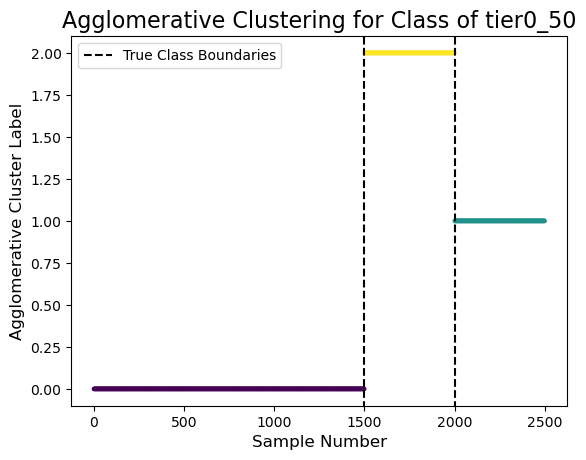

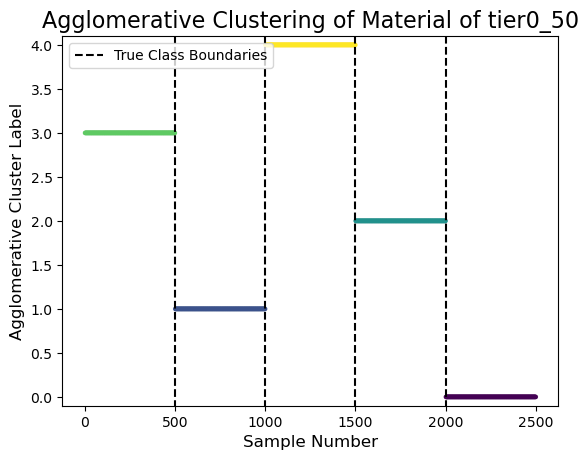

In [ ]:
# class
ac3 = AgglomerativeClustering(n_clusters=3)
aclusters3 = ac3.fit_predict(X_tier0)
aclabels3 = ac3.labels_

plt.scatter(sample_numbers, aclusters3, c=aclusters3, alpha=0.5, s=5, cmap='viridis')
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('Agglomerative Cluster Label', fontsize=12)
plt.vlines(x=[1500, 2000], ymin=-.25, ymax = 2.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 2.1)
plt.title('Agglomerative Clustering for Class of tier0_50', fontsize=16)
plt.legend()
plt.show()

# material
ac5 = AgglomerativeClustering(n_clusters=5)
aclusters5 = ac5.fit_predict(X_tier0)
aclabels5 = ac5.labels_

plt.scatter(sample_numbers, aclusters5, c=aclusters5, alpha=0.5, s=5, cmap='viridis')
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('Agglomerative Cluster Label', fontsize=12)
plt.vlines(x=[500, 1000, 1500, 2000], ymin=-.25, ymax = 4.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 4.1)
plt.title('Agglomerative Clustering of Material of tier0_50', fontsize=16)
plt.legend(loc="upper left")
plt.show()

Gaussian Mixture Option

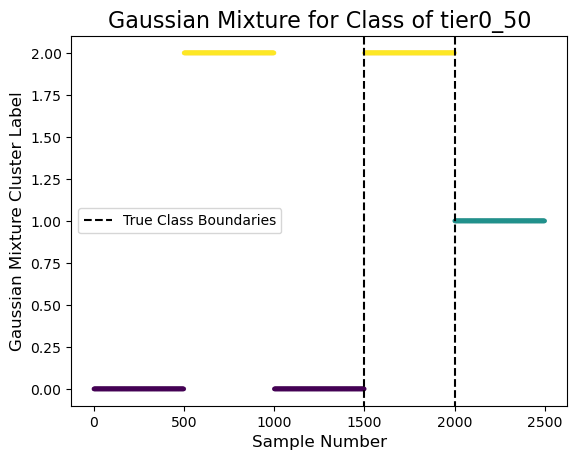

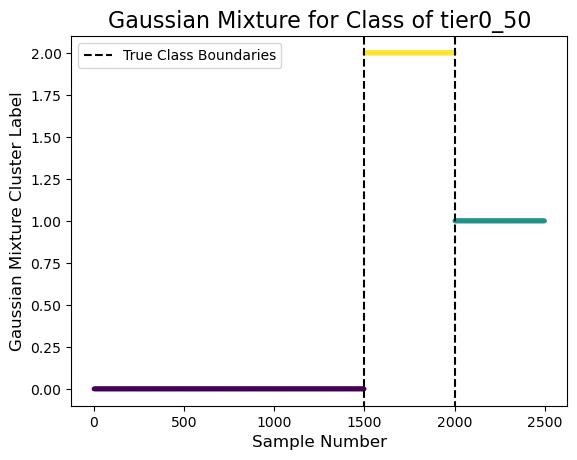

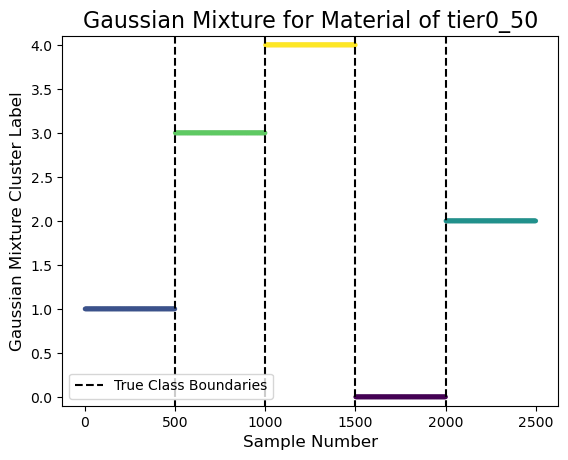

In [ ]:
# class

# not set seed, and occassionally get interesting result that the 2nd Al set more closely aligns with high Z than the benign class
# random_state = 1 is one of the few instances where this does happen. The typical result (which more closely matches the truth) is the second image

gm = GaussianMixture(n_components=3, random_state=1)
gm.fit(X_tier0)
gmlabels = gm.predict(X_tier0)
plt.scatter(sample_numbers, gmlabels, c=gmlabels, alpha=0.5, s=5, cmap='viridis')
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('Gaussian Mixture Cluster Label', fontsize=12)
plt.vlines(x=[1500, 2000], ymin=-.25, ymax = 2.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 2.1)
plt.title('Gaussian Mixture for Class of tier0_50', fontsize=16)
plt.legend()
plt.show()

# not set seed, and occassionally get interesting result that the 2nd Al set more closely aligns with high Z than the benign class

gm = GaussianMixture(n_components=3, random_state=2)
gm.fit(X_tier0)
gmlabels = gm.predict(X_tier0)
plt.scatter(sample_numbers, gmlabels, c=gmlabels, alpha=0.5, s=5, cmap='viridis')
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('Gaussian Mixture Cluster Label', fontsize=12)
plt.vlines(x=[1500, 2000], ymin=-.25, ymax = 2.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 2.1)
plt.title('Gaussian Mixture for Class of tier0_50', fontsize=16)
plt.legend()
plt.show()

#material 

gm = GaussianMixture(n_components=5)
gm.fit(X_tier0)
gmlabels = gm.predict(X_tier0)
plt.scatter(sample_numbers, gmlabels, c=gmlabels, alpha=0.5, s=5, cmap='viridis')
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('Gaussian Mixture Cluster Label', fontsize=12)
plt.vlines(x=[500, 1000, 1500, 2000], ymin=-.25, ymax = 4.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 4.1)
plt.title('Gaussian Mixture for Material of tier0_50', fontsize=16)
plt.legend()
plt.show()

### B) Supervised Learning ###

Random Forest

Class accuracy: 1.0
Material accuracy: 1.0
Counts of predicted class labels: Counter({np.int64(0): 310, np.int64(1): 104, np.int64(2): 86})
Counts of predicted material labels: Counter({np.int64(3): 111, np.int64(2): 108, np.int64(1): 100, np.int64(4): 93, np.int64(0): 88})


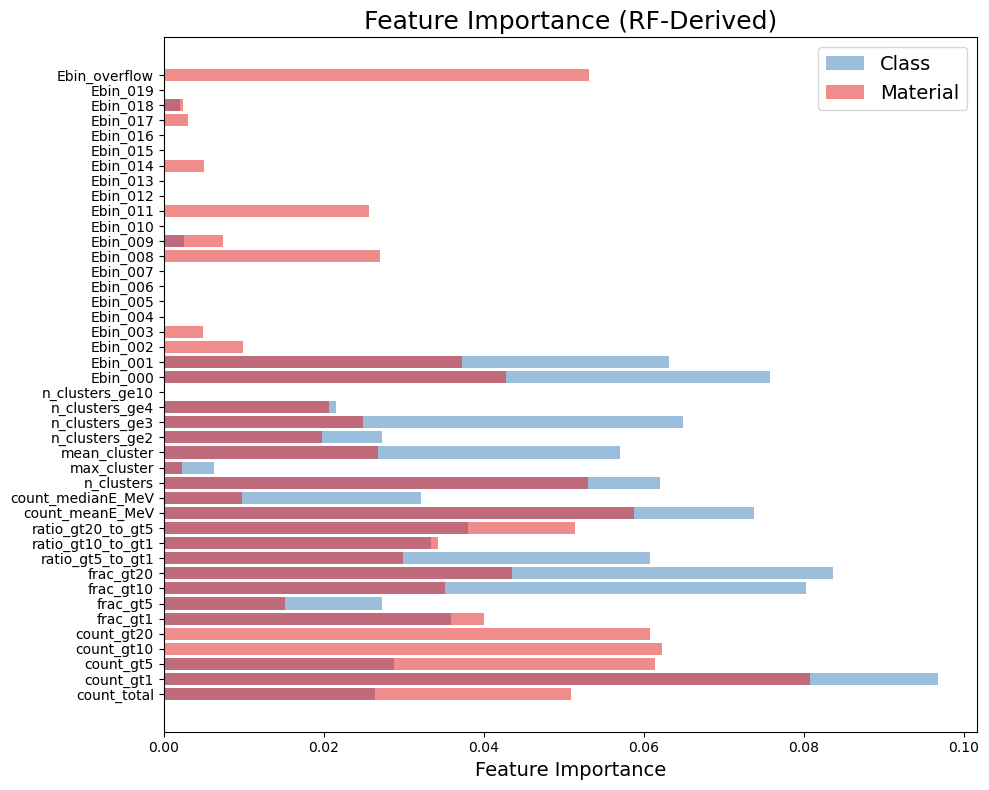

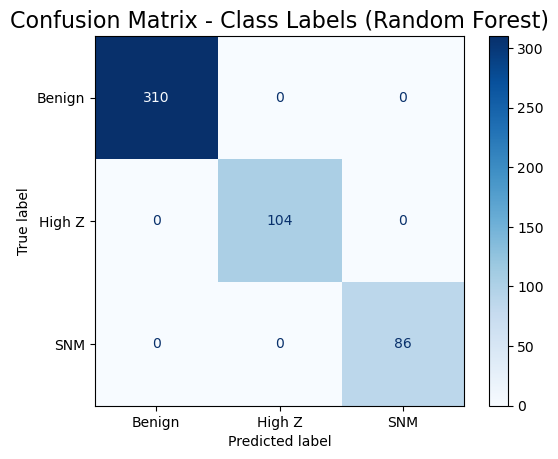

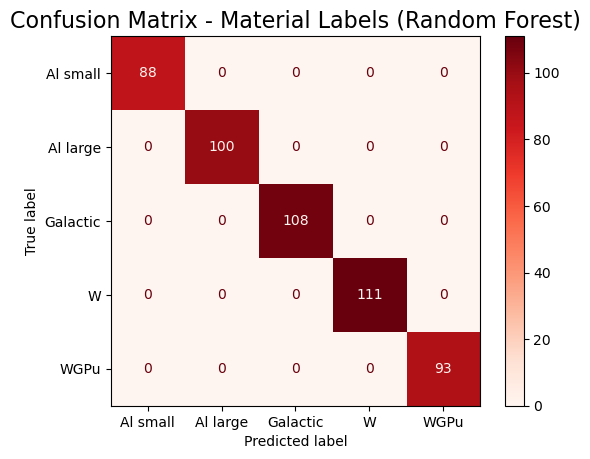

In [ ]:
# class labels only

X_train, X_test, encoded_class_labels_train, encoded_class_labels_test = train_test_split(X_tier0, encoded_class_labels, test_size=0.2)

rf_class = RandomForestClassifier(n_estimators=100, max_depth=None, min_samples_split=2, random_state=42)
rf_class.fit(X_train, encoded_class_labels_train)
Y_pred_rf_class = rf_class.predict(X_test)

# material labels only

X_train, X_test, encoded_material_labels_train, encoded_material_labels_test = train_test_split(X_tier0, encoded_material_labels, test_size=0.2, random_state=42)

rf_material = RandomForestClassifier(n_estimators=100, max_depth=None, min_samples_split=2, random_state=42)
rf_material.fit(X_train, encoded_material_labels_train)
Y_pred_rf_material = rf_material.predict(X_test)

print("Class accuracy:", accuracy_score(encoded_class_labels_test, Y_pred_rf_class))
print("Material accuracy:", accuracy_score(encoded_material_labels_test, Y_pred_rf_material))

print("Counts of predicted class labels:", Counter(Y_pred_rf_class))
print("Counts of predicted material labels:", Counter(Y_pred_rf_material))

plt.figure(figsize=(10, 8))
plt.barh(range(len(feature_labels)), rf_class.feature_importances_, alpha=0.5, color = '#377eb8')
plt.barh(range(len(feature_labels)), rf_material.feature_importances_, alpha=0.5, color = '#e41a1c')
plt.yticks(range(len(feature_labels)), feature_labels, fontsize=10)
plt.xlabel("Feature Importance", fontsize=14)
plt.title("Feature Importance (RF-Derived)", fontsize=18)
plt.tight_layout()
plt.legend(['Class', 'Material'], loc='upper right', fontsize=14)
plt.show()

# confusion matrices

cm_class = confusion_matrix(encoded_class_labels_test, Y_pred_rf_class)

disp_class = ConfusionMatrixDisplay(confusion_matrix=cm_class, display_labels=["Benign", "High Z", "SNM"])
disp_class.plot(cmap="Blues")
plt.title("Confusion Matrix - Class Labels (Random Forest)", fontsize=16)
plt.show()

cm_material = confusion_matrix(encoded_material_labels_test, Y_pred_rf_material)

disp_material = ConfusionMatrixDisplay(confusion_matrix=cm_material, display_labels=["Al small", "Al large", "Galactic", "W", "WGPu"])
disp_material.plot(cmap="Reds")
plt.title("Confusion Matrix - Material Labels (Random Forest)", fontsize=16)
plt.show()

Gradient Boosting

Class accuracy: 1.0
Material accuracy: 1.0
Counts of predicted class labels: Counter({np.int64(0): 327, np.int64(2): 96, np.int64(1): 77})
Counts of predicted material labels: Counter({np.int64(0): 121, np.int64(1): 106, np.int64(2): 100, np.int64(4): 96, np.int64(3): 77})


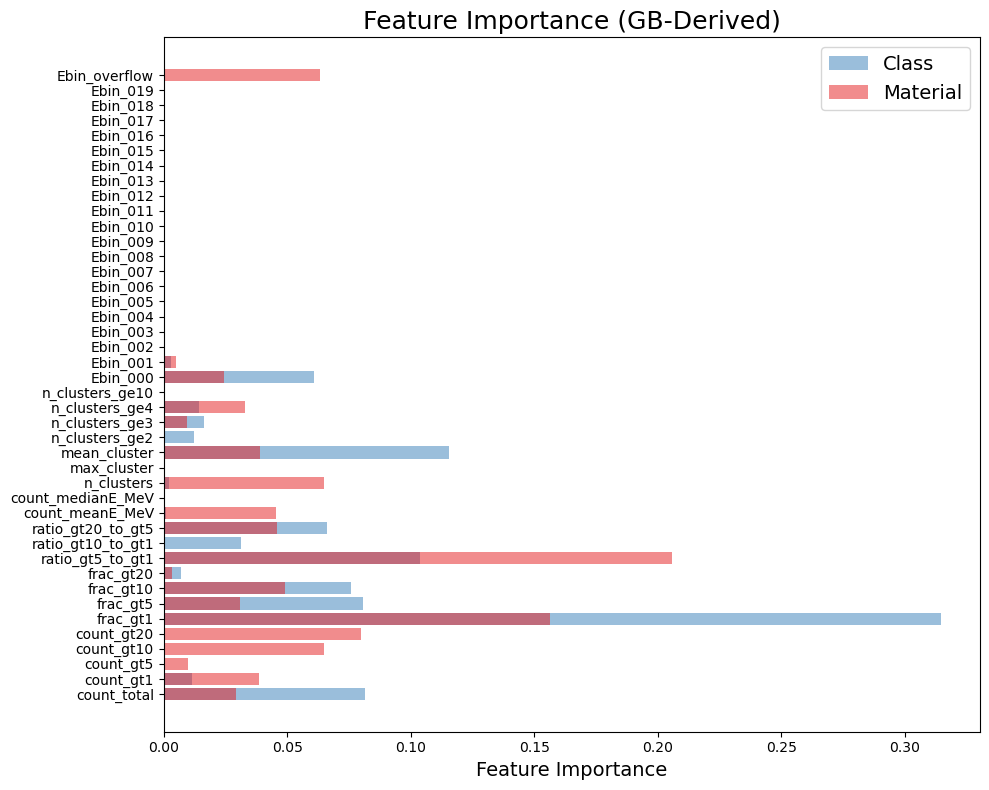

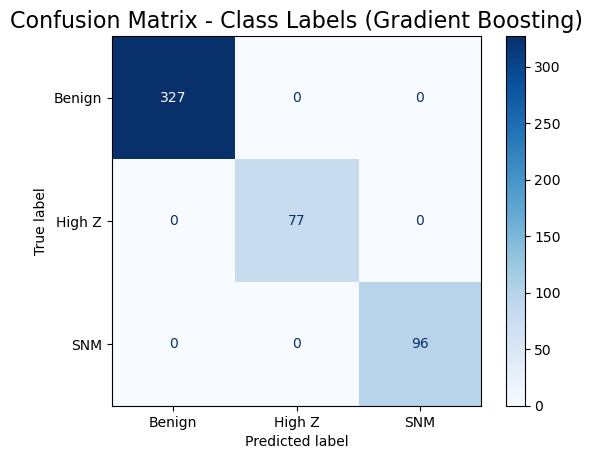

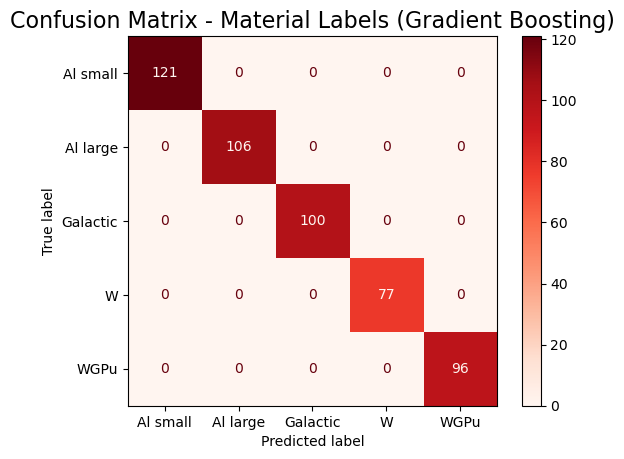

In [ ]:
# can do materials and class together with a multioutput classifier on gradient boosting

X_train, X_test, encoded_all_outputs_train, encoded_all_outputs_test = train_test_split(X_tier0, encoded_all_outputs, test_size=0.2)

gb = GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=42)
gb_multi = MultiOutputClassifier(gb)
gb_multi.fit(X_train, encoded_all_outputs_train)

Y_pred_gb = gb_multi.predict(X_test)

print("Class accuracy:", accuracy_score(encoded_all_outputs_test[:,0], Y_pred_gb[:,0]))
print("Material accuracy:", accuracy_score(encoded_all_outputs_test[:,1], Y_pred_gb[:,1]))

print("Counts of predicted class labels:", Counter(encoded_all_outputs_test[:,0]))
print("Counts of predicted material labels:", Counter(encoded_all_outputs_test[:,1]))

plt.figure(figsize=(10, 8))
plt.barh(range(len(feature_labels)), gb_multi.estimators_[0].feature_importances_, alpha=0.5, color='#377eb8')
plt.barh(range(len(feature_labels)), gb_multi.estimators_[1].feature_importances_, alpha=0.5, color='#e41a1c')
plt.yticks(range(len(feature_labels)), feature_labels)
plt.xlabel("Feature Importance", fontsize=14)
plt.title("Feature Importance (GB-Derived)", fontsize=18)
plt.legend(['Class', 'Material'], loc='upper right', fontsize=14)
plt.tight_layout()
plt.show()

# confusion matrices

cm_class = confusion_matrix(encoded_all_outputs_test[:,0], Y_pred_gb[:,0])
disp_class = ConfusionMatrixDisplay(confusion_matrix=cm_class, display_labels=["Benign", "High Z", "SNM"])
disp_class.plot(cmap="Blues")
plt.title("Confusion Matrix - Class Labels (Gradient Boosting)", fontsize=16)
plt.show()

cm_material = confusion_matrix(encoded_all_outputs_test[:,1], Y_pred_gb[:,1])

disp_material = ConfusionMatrixDisplay(confusion_matrix=cm_material, display_labels=["Al small", "Al large", "Galactic", "W", "WGPu"])
disp_material.plot(cmap="Reds")
plt.title("Confusion Matrix - Material Labels (Gradient Boosting)", fontsize=16)
plt.show()

# Put it all together for a script

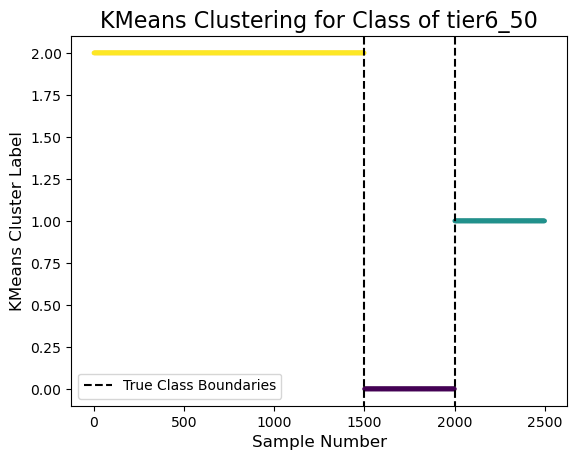

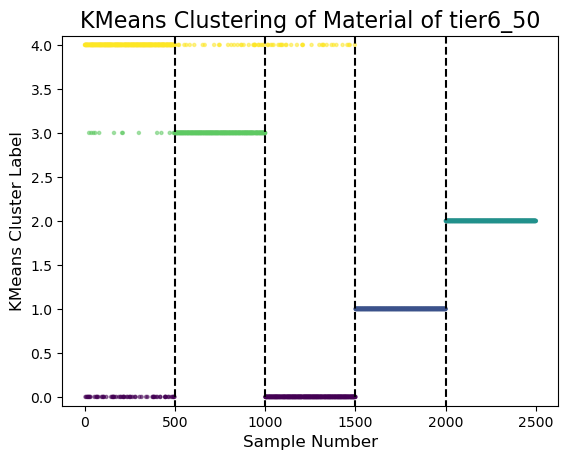

KMeans with 3 clusters - AMI: 1.0000, ARI: 1.0000, Accuracy: 0.0000
KMeans with 5 clusters - AMI: 0.8802, ARI: 0.8750, Accuracy: 0.0000


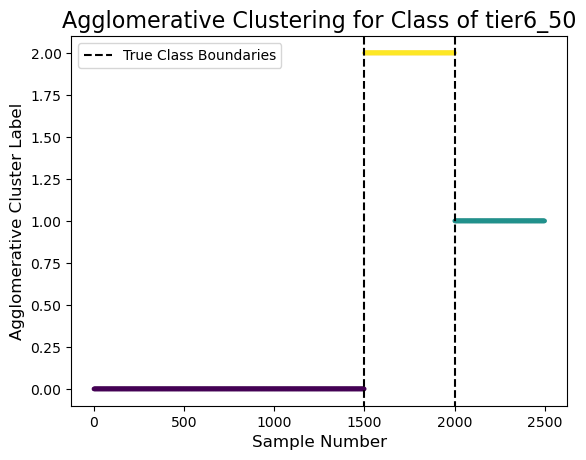

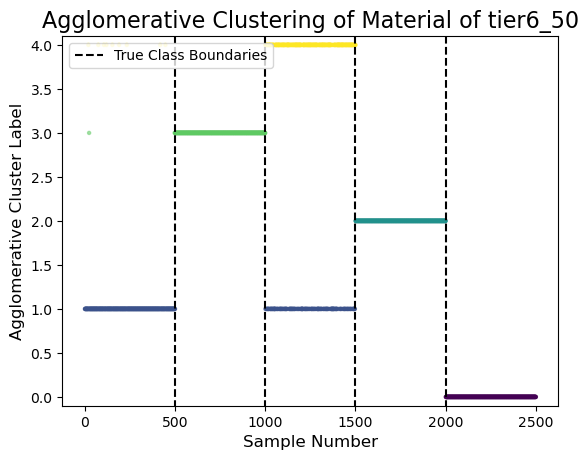

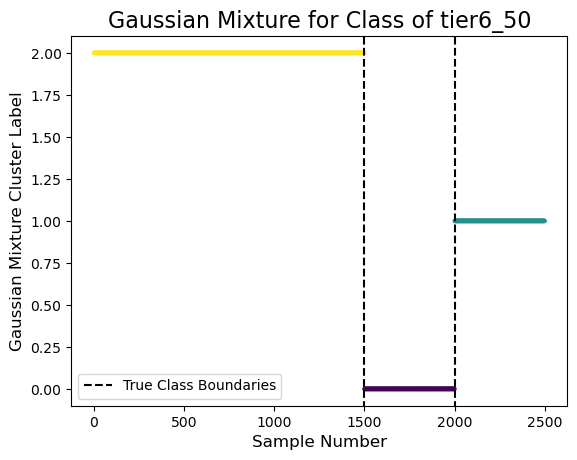

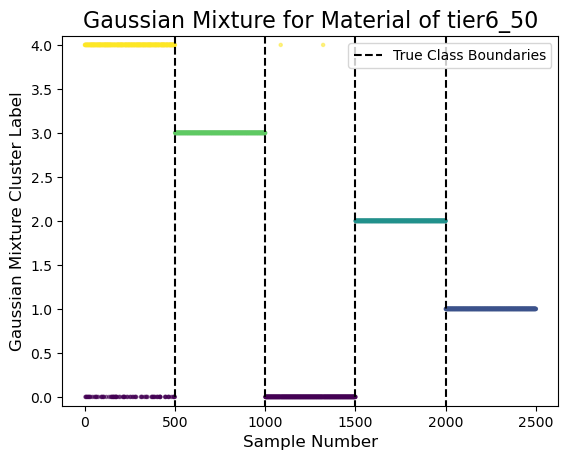

Class accuracy: 1.0
Material accuracy: 0.99
Counts of predicted class labels: Counter({np.int64(0): 289, np.int64(1): 107, np.int64(2): 104})
Counts of predicted material labels: Counter({np.int64(3): 111, np.int64(2): 107, np.int64(1): 101, np.int64(4): 93, np.int64(0): 88})


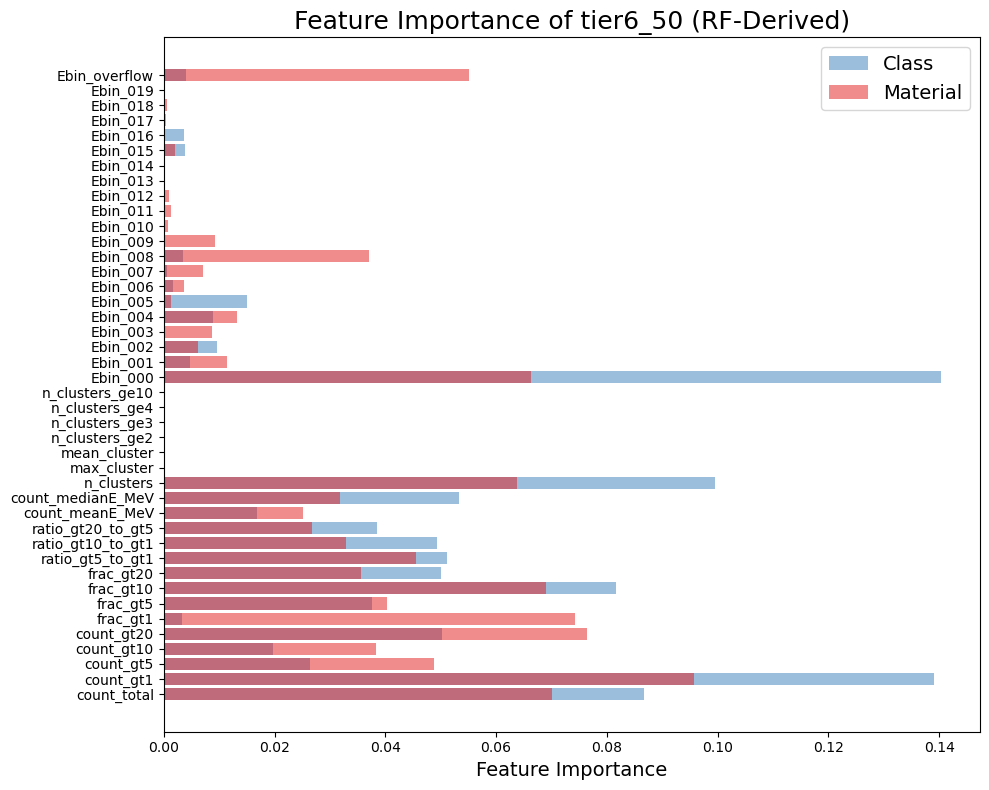

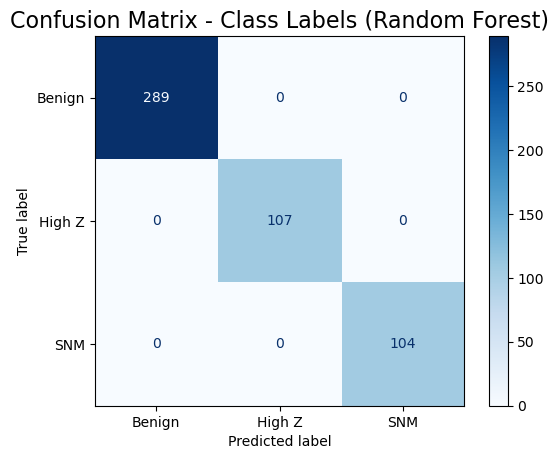

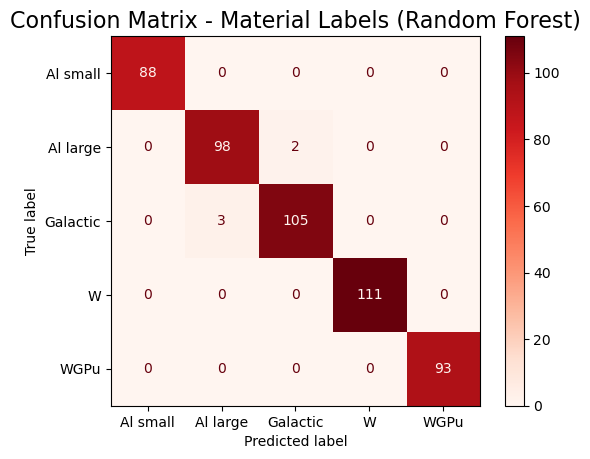

Class accuracy: 0.998
Material accuracy: 0.994
Counts of predicted class labels: Counter({np.int64(0): 286, np.int64(2): 111, np.int64(1): 103})
Counts of predicted material labels: Counter({np.int64(1): 112, np.int64(4): 111, np.int64(3): 103, np.int64(2): 91, np.int64(0): 83})


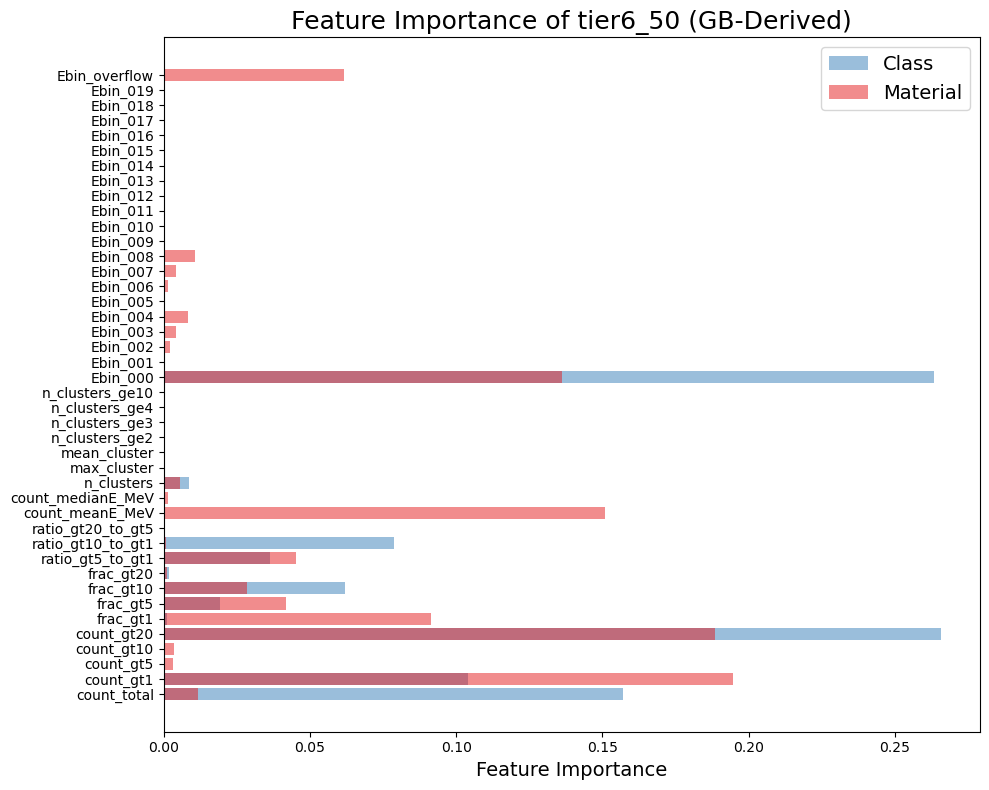

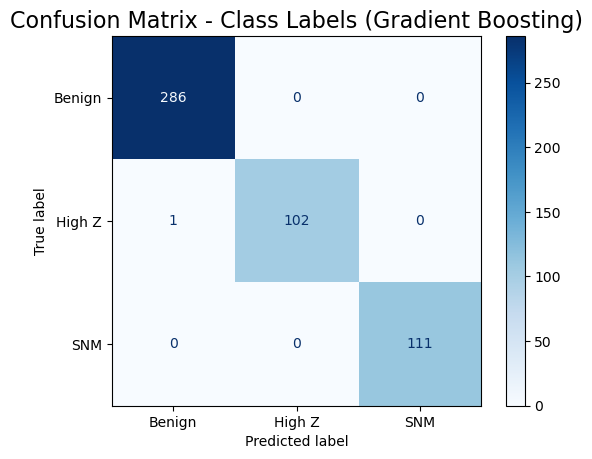

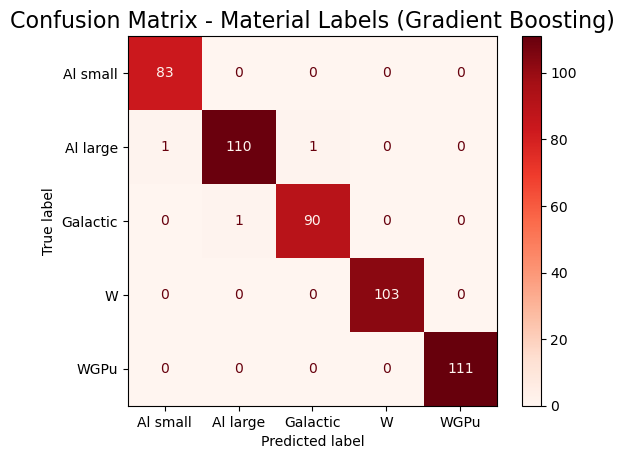

In [ ]:
#########################################################################################################################################
#                                                                                                                                       #
#                           Change this information for each dataset, everything else should be good to go                              #
#                                                                                                                                       #
##################################3######################################################################################################

# All predictive data (Previous columns are sampling data, so I'm starting from column 8)
X_data = tier6_50.iloc[:, 8:]

# name for plotting
data_name = "tier6_50"

########################################################################################################################################
########################################################################################################################################
########################################################################################################################################

# Standardize the data
scaler = StandardScaler()
X_data_scaled = scaler.fit_transform(X_data)

# Testing 3 clusters, and comparing against the true class labels (3 classes)
km3 = KMeans(n_clusters=3, n_init=30, random_state=42)
km3.fit(X_data)
kmlabels3 = km3.labels_

plt.scatter(sample_numbers, kmlabels3, c=kmlabels3, alpha=0.5, s=5, cmap='viridis')
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('KMeans Cluster Label', fontsize=12)
plt.vlines(x=[1500, 2000], ymin=-.25, ymax = 2.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 2.1)
plt.title('KMeans Clustering for Class of ' + data_name, fontsize=16)
plt.legend()
plt.show()

# Testing 5 clusters, and comparing against the true material labels (5 materials)
km5 = KMeans(n_clusters=5, n_init=30, random_state=42)
km5.fit(X_data)
kmlabels5 = km5.labels_

plt.scatter(sample_numbers, kmlabels5, alpha=0.5, c=kmlabels5, s=5, cmap='viridis')
plt.vlines(x=[500, 1000, 1500, 2000], ymin=-.25, ymax = 4.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 4.1)
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('KMeans Cluster Label', fontsize=12)
plt.title('KMeans Clustering of Material of ' + data_name, fontsize=16)
plt.show()

#Print Statistics results --> still should figure out accuracy, I think it's a data type issue with the labels, but not fully sure yet
AMI_km3 = adjusted_mutual_info_score(class_labels, kmlabels3)
ARI_km3 = adjusted_rand_score(class_labels, kmlabels3)
accuracy_km3 = accuracy_score(np.array(class_labels), kmlabels3)

#print(type(np.array(class_labels)), type(kmlabels3))

print(f"KMeans with 3 clusters - AMI: {AMI_km3:.4f}, ARI: {ARI_km3:.4f}, Accuracy: {accuracy_km3:.4f}")

AMI_km5 = adjusted_mutual_info_score(material_labels, kmlabels5)
ARI_km5 = adjusted_rand_score(material_labels, kmlabels5)
accuracy_km5 = accuracy_score(np.array(material_labels), kmlabels5)

print(f"KMeans with 5 clusters - AMI: {AMI_km5:.4f}, ARI: {ARI_km5:.4f}, Accuracy: {accuracy_km5:.4f}")

#######################################################################################################################################

#Aggolomerative Clustering

# class
ac3 = AgglomerativeClustering(n_clusters=3)
aclusters3 = ac3.fit_predict(X_data)
aclabels3 = ac3.labels_

plt.scatter(sample_numbers, aclusters3, c=aclusters3, alpha=0.5, s=5, cmap='viridis')
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('Agglomerative Cluster Label', fontsize=12)
plt.vlines(x=[1500, 2000], ymin=-.25, ymax = 2.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 2.1)
plt.title('Agglomerative Clustering for Class of ' + data_name, fontsize=16)
plt.legend()
plt.show()

# material
ac5 = AgglomerativeClustering(n_clusters=5)
aclusters5 = ac5.fit_predict(X_data)
aclabels5 = ac5.labels_

plt.scatter(sample_numbers, aclusters5, c=aclusters5, alpha=0.5, s=5, cmap='viridis')
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('Agglomerative Cluster Label', fontsize=12)
plt.vlines(x=[500, 1000, 1500, 2000], ymin=-.25, ymax = 4.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 4.1)
plt.title('Agglomerative Clustering of Material of ' + data_name, fontsize=16)
plt.legend(loc="upper left")
plt.show()

#######################################################################################################################################

# Gaussian Mixture

# class

# not set seed, and occassionally get interesting result that the 2nd Al set more closely aligns with high Z than the benign class
# random_state = 1 is one of the few instances where this does happen. The typical result (which more closely matches the truth) is the second image

gm = GaussianMixture(n_components=3)
gm.fit(X_data)
gmlabels = gm.predict(X_data)
plt.scatter(sample_numbers, gmlabels, c=gmlabels, alpha=0.5, s=5, cmap='viridis')
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('Gaussian Mixture Cluster Label', fontsize=12)
plt.vlines(x=[1500, 2000], ymin=-.25, ymax = 2.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 2.1)
plt.title('Gaussian Mixture for Class of ' + data_name, fontsize=16)
plt.legend()
plt.show()

#material 

gm = GaussianMixture(n_components=5)
gm.fit(X_data)
gmlabels = gm.predict(X_data)
plt.scatter(sample_numbers, gmlabels, c=gmlabels, alpha=0.5, s=5, cmap='viridis')
plt.xlabel('Sample Number', fontsize=12)
plt.ylabel('Gaussian Mixture Cluster Label', fontsize=12)
plt.vlines(x=[500, 1000, 1500, 2000], ymin=-.25, ymax = 4.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 4.1)
plt.title('Gaussian Mixture for Material of ' + data_name, fontsize=16)
plt.legend()
plt.show()

#######################################################################################################################################

#Random Forest

# class labels only

X_train, X_test, encoded_class_labels_train, encoded_class_labels_test = train_test_split(X_data, encoded_class_labels, test_size=0.2)

rf_class = RandomForestClassifier(n_estimators=100, max_depth=None, min_samples_split=2, random_state=42)
rf_class.fit(X_train, encoded_class_labels_train)
Y_pred_rf_class = rf_class.predict(X_test)

# material labels only

X_train, X_test, encoded_material_labels_train, encoded_material_labels_test = train_test_split(X_data, encoded_material_labels, test_size=0.2, random_state=42)

rf_material = RandomForestClassifier(n_estimators=100, max_depth=None, min_samples_split=2, random_state=42)
rf_material.fit(X_train, encoded_material_labels_train)
Y_pred_rf_material = rf_material.predict(X_test)

print("Class accuracy:", accuracy_score(encoded_class_labels_test, Y_pred_rf_class))
print("Material accuracy:", accuracy_score(encoded_material_labels_test, Y_pred_rf_material))

print("Counts of predicted class labels:", Counter(Y_pred_rf_class))
print("Counts of predicted material labels:", Counter(Y_pred_rf_material))

plt.figure(figsize=(10, 8))
plt.barh(range(len(feature_labels)), rf_class.feature_importances_, alpha=0.5, color = '#377eb8')
plt.barh(range(len(feature_labels)), rf_material.feature_importances_, alpha=0.5, color = '#e41a1c')
plt.yticks(range(len(feature_labels)), feature_labels, fontsize=10)
plt.xlabel("Feature Importance", fontsize=14)
plt.title("Feature Importance of " + data_name + " (RF-Derived)", fontsize=18)
plt.tight_layout()
plt.legend(['Class', 'Material'], loc='upper right', fontsize=14)
plt.show()

# confusion matrices

cm_class = confusion_matrix(encoded_class_labels_test, Y_pred_rf_class)

disp_class = ConfusionMatrixDisplay(confusion_matrix=cm_class, display_labels=["Benign", "High Z", "SNM"])
disp_class.plot(cmap="Blues")
plt.title("Confusion Matrix - Class Labels (Random Forest)", fontsize=16)
plt.show()

cm_material = confusion_matrix(encoded_material_labels_test, Y_pred_rf_material)

disp_material = ConfusionMatrixDisplay(confusion_matrix=cm_material, display_labels=["Al small", "Al large", "Galactic", "W", "WGPu"])
disp_material.plot(cmap="Reds")
plt.title("Confusion Matrix - Material Labels (Random Forest)", fontsize=16)
plt.show()

#######################################################################################################################################

# Gradient Boosting

# can do materials and class together with a multioutput classifier on gradient boosting

X_train, X_test, encoded_all_outputs_train, encoded_all_outputs_test = train_test_split(X_data, encoded_all_outputs, test_size=0.2)

gb = GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=42)
gb_multi = MultiOutputClassifier(gb)
gb_multi.fit(X_train, encoded_all_outputs_train)

Y_pred_gb = gb_multi.predict(X_test)

print("Class accuracy:", accuracy_score(encoded_all_outputs_test[:,0], Y_pred_gb[:,0]))
print("Material accuracy:", accuracy_score(encoded_all_outputs_test[:,1], Y_pred_gb[:,1]))

print("Counts of predicted class labels:", Counter(encoded_all_outputs_test[:,0]))
print("Counts of predicted material labels:", Counter(encoded_all_outputs_test[:,1]))

plt.figure(figsize=(10, 8))
plt.barh(range(len(feature_labels)), gb_multi.estimators_[0].feature_importances_, alpha=0.5, color='#377eb8')
plt.barh(range(len(feature_labels)), gb_multi.estimators_[1].feature_importances_, alpha=0.5, color='#e41a1c')
plt.yticks(range(len(feature_labels)), feature_labels)
plt.xlabel("Feature Importance", fontsize=14)
plt.title("Feature Importance of " + data_name + " (GB-Derived)", fontsize=18)
plt.legend(['Class', 'Material'], loc='upper right', fontsize=14)
plt.tight_layout()
plt.show()

# confusion matrices

cm_class = confusion_matrix(encoded_all_outputs_test[:,0], Y_pred_gb[:,0])
disp_class = ConfusionMatrixDisplay(confusion_matrix=cm_class, display_labels=["Benign", "High Z", "SNM"])
disp_class.plot(cmap="Blues")
plt.title("Confusion Matrix - Class Labels (Gradient Boosting)", fontsize=16)
plt.show()

cm_material = confusion_matrix(encoded_all_outputs_test[:,1], Y_pred_gb[:,1])

disp_material = ConfusionMatrixDisplay(confusion_matrix=cm_material, display_labels=["Al small", "Al large", "Galactic", "W", "WGPu"])
disp_material.plot(cmap="Reds")
plt.title("Confusion Matrix - Material Labels (Gradient Boosting)", fontsize=16)
plt.show()


  6 m: class balanced accuracy = 1.0000, material balanced accuracy = 1.0000
  8 m: class balanced accuracy = 1.0000, material balanced accuracy = 1.0000
 10 m: class balanced accuracy = 1.0000, material balanced accuracy = 1.0000
 15 m: class balanced accuracy = 1.0000, material balanced accuracy = 0.9920
 20 m: class balanced accuracy = 1.0000, material balanced accuracy = 0.9900
 30 m: class balanced accuracy = 0.9922, material balanced accuracy = 0.9700
 40 m: class balanced accuracy = 0.9756, material balanced accuracy = 0.9640
 50 m: class balanced accuracy = 0.9122, material balanced accuracy = 0.8740
 75 m: class balanced accuracy = 0.7600, material balanced accuracy = 0.8220
100 m: class balanced accuracy = 0.4689, material balanced accuracy = 0.4200

Tier 6 highgt60 SC50 Gradient Boosting balanced-accuracy results:
 distance_m  class_balanced_accuracy  material_balanced_accuracy
          6                 1.000000                       1.000
          8                 1.000

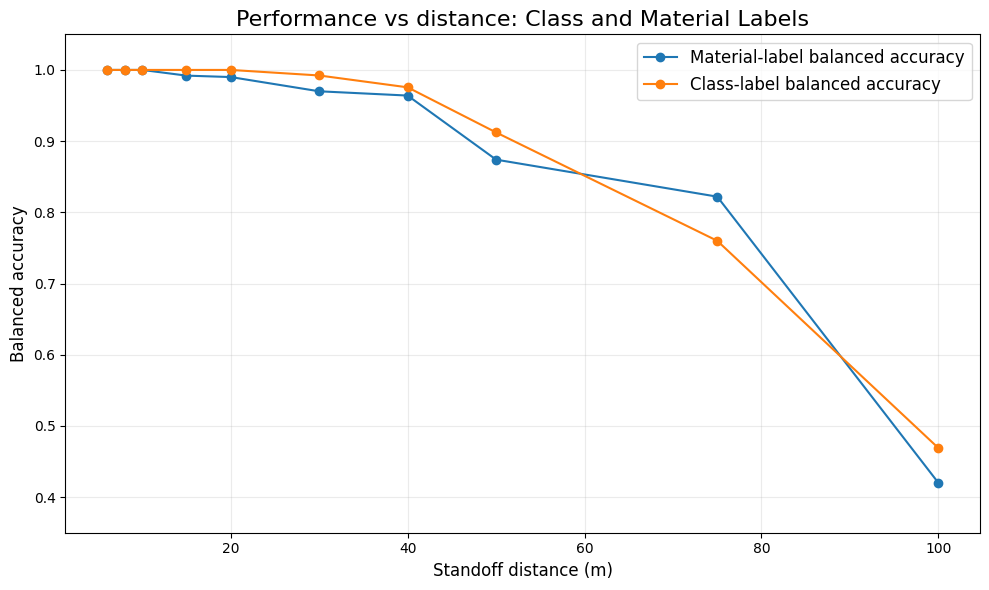

In [3]:
# tier6_highgt60 SC50 distances in the new data files
tier6_distances_m = [6, 8, 10, 15, 20, 30, 40, 50, 75, 100]


# Read SC50 file, had to have extra code for mult paths since mine wasn't accepting
# the pathing above
def read_tier6_sc50_csv(distance_m):
    filename = f"tier6_highgt60_dist_{distance_m}m_sc50.csv"

    possible_paths = [
        "./data/" + filename,
        ".\\data\\" + filename,
        filename,
    ]

    for path in possible_paths:
        try:
            return pd.read_csv(path)
        except FileNotFoundError:
            pass

    raise FileNotFoundError(
        "Could not find " + filename + " in any of these locations: " + ", ".join(possible_paths)
    )


# function to get the encoded outputs and material labels 
def make_encoded_outputs_for_tier6(df):
    class_labels_this = df["class_label"].to_numpy().copy()

    material_labels_this = df["snmMaterial"].astype(object).to_numpy().copy()
    material_labels_this[0:500] = "G4_Al_small"
    material_labels_this[500:1000] = "G4_Al_large"

    encoded_class_labels_this = LabelEncoder().fit_transform(class_labels_this)
    encoded_material_labels_this = LabelEncoder().fit_transform(material_labels_this)

    encoded_outputs_this = np.column_stack(
        (encoded_class_labels_this, encoded_material_labels_this)
    )

    return encoded_outputs_this, encoded_material_labels_this


# function to compute balanced accuracy from confusion matrix
# since I don't want to add a new sklearn import just for this metric
def balanced_accuracy_from_confusion(y_true, y_pred):
    
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    recall_by_label = np.diag(cm) / cm.sum(axis=1)

    return np.mean(recall_by_label)


tier6_gb_rows = []

for distance_m in tier6_distances_m:
    tier6_df = read_tier6_sc50_csv(distance_m)
    X_tier6 = tier6_df.iloc[:, 8:]

    encoded_outputs, encoded_material_labels_this = make_encoded_outputs_for_tier6(tier6_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X_tier6,
        encoded_outputs,
        test_size=0.2,
        random_state=42,
        stratify=encoded_material_labels_this,
    )

    gb = GradientBoostingClassifier(
        n_estimators=500,
        learning_rate=0.1,
        max_depth=3,
        random_state=42,
    )

    gb_multi = MultiOutputClassifier(gb)
    gb_multi.fit(X_train, y_train)

    y_pred = gb_multi.predict(X_test)

    class_bal_acc = balanced_accuracy_from_confusion(y_test[:, 0], y_pred[:, 0])
    material_bal_acc = balanced_accuracy_from_confusion(y_test[:, 1], y_pred[:, 1])

    tier6_gb_rows.append(
        {
            "distance_m": distance_m,
            "class_balanced_accuracy": class_bal_acc,
            "material_balanced_accuracy": material_bal_acc,
        }
    )

    print(
        f"{distance_m:>3} m: "
        f"class balanced accuracy = {class_bal_acc:.4f}, "
        f"material balanced accuracy = {material_bal_acc:.4f}"
    )


tier6_gb_results_sc50 = (
    pd.DataFrame(tier6_gb_rows)
    .sort_values("distance_m")
    .reset_index(drop=True)
)

print("\nTier 6 highgt60 SC50 Gradient Boosting balanced-accuracy results:")
print(tier6_gb_results_sc50.to_string(index=False))



# Plot balanced accuracy vs distance

plt.figure(figsize=(10, 6))

plt.plot(
    tier6_gb_results_sc50["distance_m"],
    tier6_gb_results_sc50["material_balanced_accuracy"],
    marker="o",
    label="Material-label balanced accuracy",
)

plt.plot(
    tier6_gb_results_sc50["distance_m"],
    tier6_gb_results_sc50["class_balanced_accuracy"],
    marker="o",
    label="Class-label balanced accuracy",
)

plt.xlabel("Standoff distance (m)", fontsize=12)
plt.ylabel("Balanced accuracy", fontsize=12)
plt.title("Performance vs distance: Class and Material Labels", fontsize=16)
plt.grid(alpha=0.25)
plt.legend(fontsize=12)

all_acc_values = tier6_gb_results_sc50[
    ["class_balanced_accuracy", "material_balanced_accuracy"]
].to_numpy().ravel()

plt.ylim(max(0.0, min(0.35, all_acc_values.min() - 0.05)), 1.05)

plt.tight_layout()

plt.show()

Class labels in confusion-matrix order:
['Benign', 'HighZ', 'SNM']

Material labels in confusion-matrix order:
['Al large', 'Al small', 'Galactic', 'W', 'WGPu']

Raw class-label confusion matrix for 75 m:
             pred Benign  pred HighZ  pred SNM
true Benign          279          18         3
true HighZ            30          60        10
true SNM               9          16        75

Raw material-label confusion matrix for 75 m:
               pred Al large  pred Al small  pred Galactic  pred W  pred WGPu
true Al large            100              0              0       0          0
true Al small              0             78              0      17          5
true Galactic              0              0             96       4          0
true W                     1             25              0      61         13
true WGPu                  0             12              0      12         76

Class balanced accuracy from normalized confusion matrix: 0.7600
Material balanced accuracy

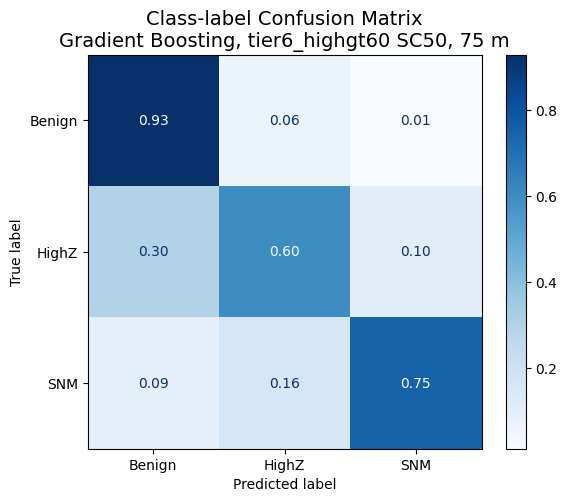

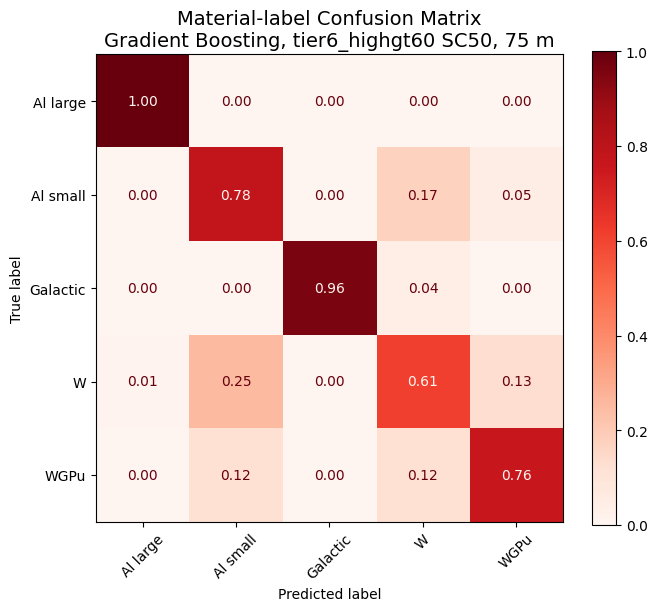

In [4]:
####################################################################################################
# Confusion matrices for one tier6_highgt60 SC50 distance
####################################################################################################

distance_to_inspect_m = 75

tier6_df = read_tier6_sc50_csv(distance_to_inspect_m)

X_tier6 = tier6_df.iloc[:, 8:]

# Build labels for this distance
class_labels_this = tier6_df["class_label"].to_numpy().copy()

material_labels_this = tier6_df["snmMaterial"].astype(object).to_numpy().copy()
material_labels_this[0:500] = "G4_Al_small"
material_labels_this[500:1000] = "G4_Al_large"

# Encode labels, keeping the encoders so the confusion-matrix display labels are in the correct order
class_encoder = LabelEncoder()
material_encoder = LabelEncoder()

encoded_class_labels_this = class_encoder.fit_transform(class_labels_this)
encoded_material_labels_this = material_encoder.fit_transform(material_labels_this)

encoded_outputs_this = np.column_stack(
    (encoded_class_labels_this, encoded_material_labels_this)
)

# Same split convention as the distance-sweep code
X_train, X_test, y_train, y_test = train_test_split(
    X_tier6,
    encoded_outputs_this,
    test_size=0.2,
    random_state=42,
    stratify=encoded_material_labels_this,
)

gb = GradientBoostingClassifier(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
)

gb_multi = MultiOutputClassifier(gb)
gb_multi.fit(X_train, y_train)

y_pred = gb_multi.predict(X_test)

# Label order used by LabelEncoder
class_display_labels = [str(label) for label in class_encoder.classes_]

material_display_labels = [
    str(label).replace("G4_", "").replace("_", " ")
    for label in material_encoder.classes_
]

print("Class labels in confusion-matrix order:")
print(class_display_labels)

print("\nMaterial labels in confusion-matrix order:")
print(material_display_labels)


####################################################################################################
# Raw-count confusion matrices
####################################################################################################

class_label_ids = np.arange(len(class_display_labels))
material_label_ids = np.arange(len(material_display_labels))

cm_class_counts = confusion_matrix(
    y_test[:, 0],
    y_pred[:, 0],
    labels=class_label_ids,
)

cm_material_counts = confusion_matrix(
    y_test[:, 1],
    y_pred[:, 1],
    labels=material_label_ids,
)

print(f"\nRaw class-label confusion matrix for {distance_to_inspect_m} m:")
print(
    pd.DataFrame(
        cm_class_counts,
        index=["true " + label for label in class_display_labels],
        columns=["pred " + label for label in class_display_labels],
    )
)

print(f"\nRaw material-label confusion matrix for {distance_to_inspect_m} m:")
print(
    pd.DataFrame(
        cm_material_counts,
        index=["true " + label for label in material_display_labels],
        columns=["pred " + label for label in material_display_labels],
    )
)


####################################################################################################
# Row-normalized confusion matrices
# Rows are true labels, columns are predicted labels.
# The diagonal values are the per-label recalls used in balanced accuracy.
####################################################################################################

cm_class_norm = confusion_matrix(
    y_test[:, 0],
    y_pred[:, 0],
    labels=class_label_ids,
    normalize="true",
)

cm_material_norm = confusion_matrix(
    y_test[:, 1],
    y_pred[:, 1],
    labels=material_label_ids,
    normalize="true",
)

print(
    f"\nClass balanced accuracy from normalized confusion matrix: "
    f"{np.diag(cm_class_norm).mean():.4f}"
)

print(
    f"Material balanced accuracy from normalized confusion matrix: "
    f"{np.diag(cm_material_norm).mean():.4f}"
)


# Class-label confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

disp_class = ConfusionMatrixDisplay(
    confusion_matrix=cm_class_norm,
    display_labels=class_display_labels,
)

disp_class.plot(
    cmap="Blues",
    values_format=".2f",
    ax=ax,
)

plt.title(
    f"Class-label Confusion Matrix\nGradient Boosting, tier6_highgt60 SC50, {distance_to_inspect_m} m",
    fontsize=14,
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()


# Material-label confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

disp_material = ConfusionMatrixDisplay(
    confusion_matrix=cm_material_norm,
    display_labels=material_display_labels,
)

disp_material.plot(
    cmap="Reds",
    values_format=".2f",
    ax=ax,
    xticks_rotation=45,
)

plt.title(
    f"Material-label Confusion Matrix\nGradient Boosting, tier6_highgt60 SC50, {distance_to_inspect_m} m",
    fontsize=14,
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()
